<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/03_entrenamiento_E1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E1 — MobileNetV2 congelada | Clasificación de enfermedades de la yuca

**Objetivo:** comparar transferencia de aprendizaje con E0, usando las mismas particiones depuradas (5.610 entrenamiento, 1.877 validación, 1.874 prueba), resolución **224×224**, semilla **42**, Adam **1e-3**, máximo **15 épocas**, `EarlyStopping(patience=4)` y **sin aumento de datos**.

**Métrica principal:** Macro-F1 en validación. **No evaluar el conjunto de prueba todavía.**

**Hipótesis previas:** H1: E1 mejora el Macro-F1 de E0 (0,4699); H2: mejora especialmente CBB y CGM; H3: el costo de entrenamiento y de inferencia será diferente por el backbone preentrenado.

**Medidas de memoria:** batch 8, shuffle de 512 ejemplos **antes** del redimensionado, paralelismo limitado, `prefetch(1)`, sin `cache()`, sin cargar todas las imágenes en NumPy, datasets finitos con cardinalidad conocida y monitoreo de RAM. Ejecuta las celdas en orden, preferentemente en una sesión nueva.

## 1. Entorno y reproducibilidad

In [1]:
%pip -q install tensorflow-datasets importlib_resources psutil

In [2]:
import os, time, gc, math, json
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import psutil

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
EPOCHS = 15
NUM_CLASSES = 5
LR = 1e-3
CLASS_NAMES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
OUTPUT_DIR = "results/e1"
os.makedirs(OUTPUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"RAM disponible: {psutil.virtual_memory().available/1024**3:.2f} GB")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM disponible: 10.82 GB


## 2. Manifiesto depurado y particiones idénticas a E0

In [3]:
URL_MANIFIESTO = (
    "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/"
    "main/results/eda/manifiesto_final_conservados.csv"
)
df_manifest = pd.read_csv(URL_MANIFIESTO)
assert {"particion", "indice"}.issubset(df_manifest.columns)
assert len(df_manifest) == 9361
assert not df_manifest.duplicated(["particion", "indice"]).any()
print(df_manifest.groupby("particion").size())

particion
test          1874
train         5610
validation    1877
dtype: int64


In [4]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava:0.1.0",
    split=["train", "validation", "test"],
    as_supervised=True, with_info=True, shuffle_files=False
)

def aplicar_manifiesto(ds, particion):
    total = int(tf.data.experimental.cardinality(ds).numpy())
    indices = set(df_manifest.loc[
        df_manifest["particion"] == particion, "indice"
    ].astype(int))
    assert indices and min(indices) >= 0 and max(indices) < total
    mascara = tf.constant([i in indices for i in range(total)], dtype=tf.bool)
    filtrado = (ds.enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato, num_parallel_calls=1))
    # El filtro pierde la cardinalidad; restaurarla evita errores de Keras
    return filtrado.apply(tf.data.experimental.assert_cardinality(len(indices)))

ds_train_final = aplicar_manifiesto(ds_train, "train")
ds_val_final = aplicar_manifiesto(ds_val, "validation")
ds_test_final = aplicar_manifiesto(ds_test, "test")
n_train, n_val, n_test = (
    int(tf.data.experimental.cardinality(ds).numpy())
    for ds in (ds_train_final, ds_val_final, ds_test_final)
)
assert (n_train, n_val, n_test) == (5610, 1877, 1874)
print("Train:", n_train, "| Validación:", n_val, "| Test reservado:", n_test)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Train: 5610 | Validación: 1877 | Test reservado: 1874


### Comprobación de integridad
La verificación SHA-256 completa ya se realizó en E0. Aquí reutilizamos el **mismo manifiesto** y verificamos sus cantidades; no recalculamos los hashes para evitar lecturas y memoria innecesarias. Si cambian los archivos o el orden de TFDS, hay que volver a verificar la integridad antes de entrenar.

## 3. Pipeline de datos con RAM limitada

In [5]:
def preprocesar(imagen, etiqueta):
    # MobileNetV2 espera valores [0,255] ANTES de su normalización.
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen, tf.cast(etiqueta, tf.int32)

# Mezclar ANTES de convertir las imágenes a tensores float32 de 224x224.
train_ds = (ds_train_final
    .shuffle(512, seed=SEED, reshuffle_each_iteration=True)
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))
val_ds = (ds_val_final
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))
# El conjunto de prueba no se procesa ni evalúa en este notebook.

x_batch, y_batch = next(iter(train_ds))
print("Batch:", x_batch.shape, x_batch.dtype, y_batch.shape)
print("Rango:", float(tf.reduce_min(x_batch)), float(tf.reduce_max(x_batch)))
assert x_batch.shape == (BATCH_SIZE, 224, 224, 3)
assert 0 <= float(tf.reduce_min(x_batch)) <= float(tf.reduce_max(x_batch)) <= 255
# Liberar referencia al lote de inspección.
del x_batch, y_batch
gc.collect()

Batch: (8, 224, 224, 3) <dtype: 'float32'> (8,)
Rango: 0.0 255.0


68

## 4. Modelo E1: backbone MobileNetV2 completamente congelado

In [6]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

base = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

entradas = layers.Input(shape=(224, 224, 3), name="imagen_0_255")
# Equivale a mobilenet_v2.preprocess_input: [0,255] -> [-1,1].
# Rescaling es serializable, a diferencia de algunas capas Lambda.
x = layers.Rescaling(scale=1.0/127.5, offset=-1.0,
                     name="normalizacion_mobilenetv2")(entradas)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
salidas = layers.Dense(NUM_CLASSES, activation="softmax")(x)
modelo_e1 = Model(entradas, salidas, name="MobileNetV2_E1")
modelo_e1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
params_entrenables = sum(int(np.prod(w.shape)) for w in modelo_e1.trainable_weights)
params_totales = modelo_e1.count_params()
assert not base.trainable and all(not capa.trainable for capa in base.layers)
print("Parámetros entrenables:", params_entrenables)
print("Parámetros totales:", params_totales)
modelo_e1.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros entrenables: 164613
Parámetros totales: 2422597


Model: "MobileNetV2_E1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_0_255 (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion_mobilenetv2       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Entrenamiento y monitoreo de RAM

In [7]:
class MonitorMemoria(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mem = psutil.virtual_memory()
        print(f"RAM al terminar época {epoch+1}: {mem.percent:.1f}% "
              f"| disponible {mem.available/1024**3:.2f} GB")

callbacks_e1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(OUTPUT_DIR, "mejor_modelo_e1.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(OUTPUT_DIR, "historial_entrenamiento.csv")
    ),
    MonitorMemoria(),
]

# Dataset FINITO, sin .repeat() ni steps_per_epoch: cada época recorre cada imagen una vez.
inicio = time.perf_counter()
historial_e1 = modelo_e1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_e1,
    verbose=1
)
tiempo_entrenamiento_e1 = time.perf_counter() - inicio
print(f"Tiempo: {tiempo_entrenamiento_e1:.2f} s")
print("Épocas ejecutadas:", len(historial_e1.history["loss"]))

Epoch 1/15
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6217 - loss: 1.0593RAM al terminar época 1: 22.6% | disponible 9.81 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 81s 81ms/step - accuracy: 0.6660 - loss: 0.9276 - val_accuracy: 0.7075 - val_loss: 0.7498
Epoch 2/15
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7133 - loss: 0.7616RAM al terminar época 2: 28.5% | disponible 9.07 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 36s 42ms/step - accuracy: 0.7187 - loss: 0.7406 - val_accuracy: 0.7363 - val_loss: 0.7053
Epoch 3/15
701/702 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7649 - loss: 0.6549RAM al terminar época 3: 26.3% | disponible 9.34 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.7594 - loss: 0.6668 - val_accuracy: 0.7645 - val_loss: 0.6520
Epoch 4/15
697/702 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7826 - loss: 0.6000RAM al terminar época 4: 28.7% | disponible 9.03 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 26s 34ms/step - accuracy: 0.7799 - loss: 0.6053 - val_accuracy

**Nota:** el checkpoint contiene el modelo con mejor `val_loss`. `EarlyStopping` restaura esos pesos al finalizar. Si Colab se reinicia, guarda el checkpoint en Drive antes de continuar; los archivos de `/content` son temporales.

## 6. Evaluación de validación (sin usar test)

In [8]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Solo etiquetas, no imágenes completas en RAM.
y_true = np.concatenate([y.numpy() for _, y in val_ds])
assert len(y_true) == n_val

# Warm-up para medir inferencia sin incluir la primera compilación.
_ = modelo_e1.predict(val_ds.take(2), verbose=0)
inicio = time.perf_counter()
probabilidades = modelo_e1.predict(val_ds, verbose=0)
tiempo_inferencia_e1 = time.perf_counter() - inicio
assert probabilidades.shape == (n_val, NUM_CLASSES)
y_pred = probabilidades.argmax(axis=1)

accuracy_e1 = accuracy_score(y_true, y_pred)
macro_f1_e1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
ms_por_imagen = tiempo_inferencia_e1 / n_val * 1000
print(f"Accuracy: {accuracy_e1:.4f}")
print(f"Macro-F1: {macro_f1_e1:.4f}")
print(f"Inferencia: {ms_por_imagen:.2f} ms/imagen")
print(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, zero_division=0
))

Accuracy: 0.7645
Macro-F1: 0.6777
Inferencia: 5.49 ms/imagen
              precision    recall  f1-score   support

         cbb       0.65      0.38      0.48       151
        cbsd       0.68      0.78      0.73       479
         cgm       0.67      0.69      0.68       257
         cmd       0.85      0.87      0.86       885
     healthy       0.77      0.54      0.64       105

    accuracy                           0.76      1877
   macro avg       0.73      0.65      0.68      1877
weighted avg       0.76      0.76      0.76      1877



## 7. Guardar métricas y gráficas

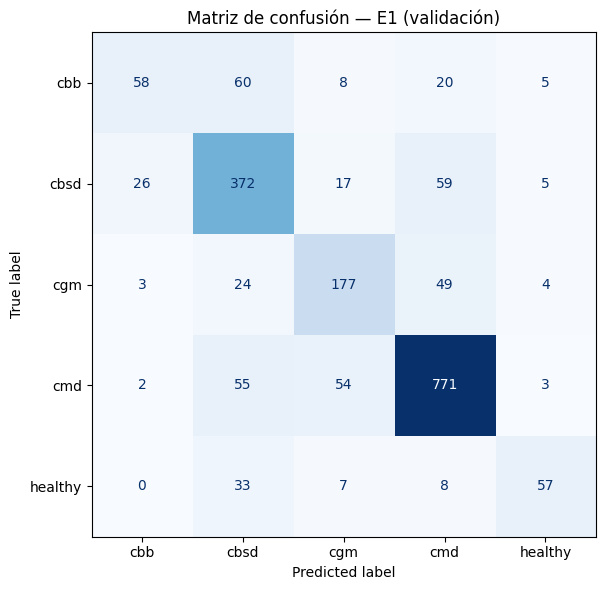

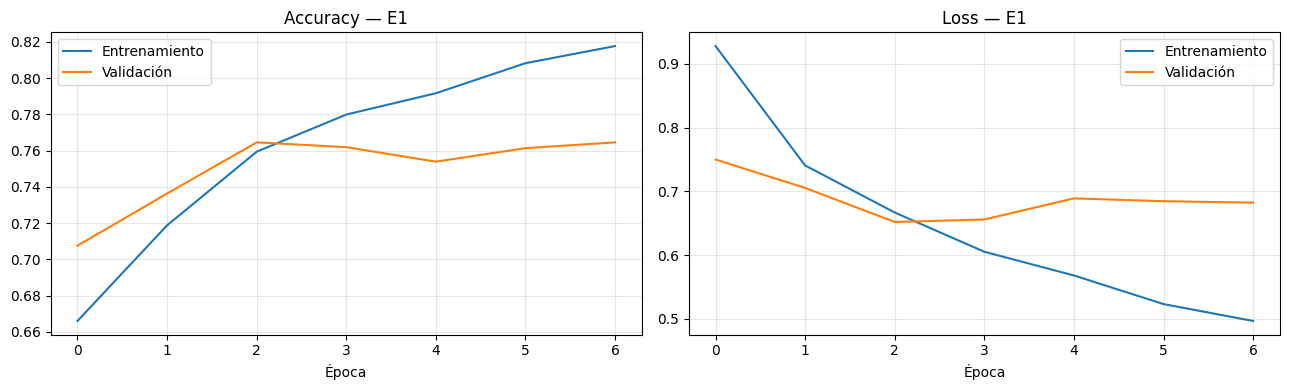

Archivos: ['historial_entrenamiento.csv', 'curvas_entrenamiento.png', 'reporte_clasificacion.csv', 'resumen_metricas.csv', 'mejor_modelo_e1.keras', 'matriz_confusion.csv', 'matriz_confusion.png']


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

reporte = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
pd.DataFrame(reporte).T.to_csv(os.path.join(OUTPUT_DIR, "reporte_clasificacion.csv"))
matriz = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
pd.DataFrame(matriz, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    os.path.join(OUTPUT_DIR, "matriz_confusion.csv")
)

ruta_modelo = os.path.join(OUTPUT_DIR, "mejor_modelo_e1.keras")
tamano_mb = os.path.getsize(ruta_modelo) / (1024**2)
pd.DataFrame([{
    "modelo": "E1_MobileNetV2_congelada",
    "accuracy": accuracy_e1,
    "macro_f1": macro_f1_e1,
    "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e1,
    "epocas_ejecutadas": len(historial_e1.history["loss"]),
    "segundos_por_epoca": tiempo_entrenamiento_e1 / len(historial_e1.history["loss"]),
    "ms_inferencia_por_imagen": ms_por_imagen,
    "tamano_modelo_MB": tamano_mb,
    "parametros_entrenables": params_entrenables,
    "parametros_totales": params_totales,
    "batch_size": BATCH_SIZE,
    "resolucion": "224x224",
    "learning_rate": LR,
    "semilla": SEED,
}]).to_csv(os.path.join(OUTPUT_DIR, "resumen_metricas.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(matriz, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Matriz de confusión — E1 (validación)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "matriz_confusion.png"), dpi=200)
plt.show()
plt.close(fig)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, clave, titulo in zip(ejes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(historial_e1.history[clave], label="Entrenamiento")
    ax.plot(historial_e1.history["val_" + clave], label="Validación")
    ax.set(xlabel="Época", title=f"{titulo} — E1")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "curvas_entrenamiento.png"), dpi=200)
plt.show()
plt.close(fig)
print("Archivos:", os.listdir(OUTPUT_DIR))

## 8. Comparación E0 vs. E1 en validación

In [10]:
# Valores de E0 documentados en el experimento anterior.
comparacion = pd.DataFrame([
    {"modelo": "E0_CNN", "accuracy": 0.6787, "macro_f1": 0.4699,
     "tiempo_entrenamiento_segundos": 495.67},
    {"modelo": "E1_MobileNetV2", "accuracy": accuracy_e1, "macro_f1": macro_f1_e1,
     "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e1},
])
print(comparacion.to_string(index=False))
comparacion.to_csv(os.path.join(OUTPUT_DIR, "comparacion_e0_e1.csv"), index=False)

        modelo  accuracy  macro_f1  tiempo_entrenamiento_segundos
        E0_CNN  0.678700  0.469900                     495.670000
E1_MobileNetV2  0.764518  0.677748                     286.504443


## 9. Inspección de ocho errores (sin cargar todas las imágenes)

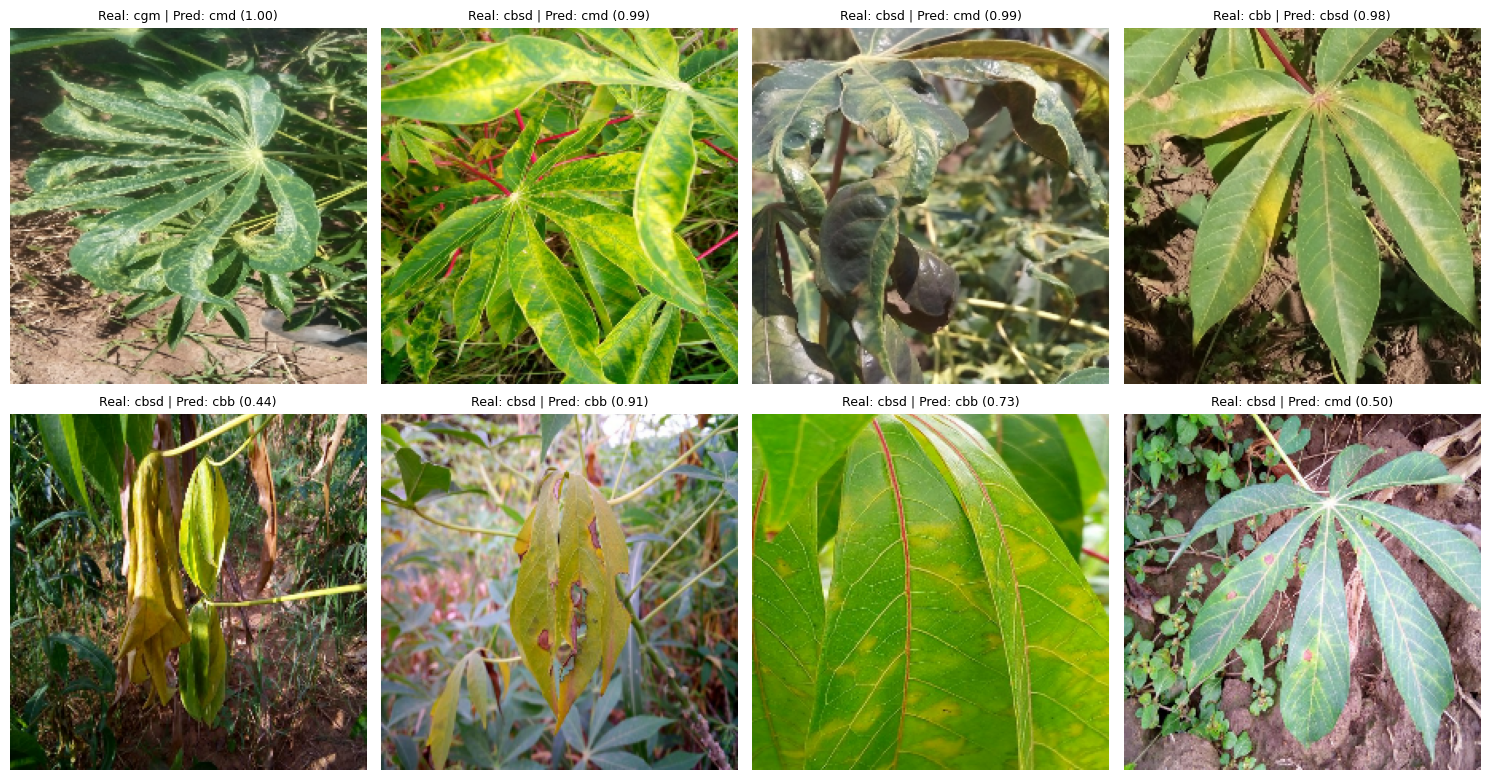

7313

In [11]:
indices_error = np.flatnonzero(y_pred != y_true)
confianza = probabilidades.max(axis=1)
assert len(indices_error) >= 8, "Se necesitan al menos ocho errores para esta inspección"

rng = np.random.default_rng(SEED)
altos = indices_error[np.argsort(-confianza[indices_error])[:4]]
restantes = np.setdiff1d(indices_error, altos)
aleatorios = rng.choice(restantes, size=4, replace=False)
seleccion = np.concatenate([altos, aleatorios])

# Solo se guardan ocho imágenes uint8, no las 1.877 de validación.
objetivos = set(int(i) for i in seleccion)
imagenes = {}
posicion = 0
for lote_x, _ in val_ds:
    for img in lote_x:
        if posicion in objetivos:
            imagenes[posicion] = np.clip(img.numpy(), 0, 255).astype(np.uint8)
        posicion += 1
    if len(imagenes) == len(objetivos):
        break
assert len(imagenes) == 8

fig, ejes = plt.subplots(2, 4, figsize=(15, 8))
for ax, indice in zip(ejes.flat, seleccion):
    indice = int(indice)
    ax.imshow(imagenes[indice])
    ax.set_title(f"Real: {CLASS_NAMES[y_true[indice]]} | "
                 f"Pred: {CLASS_NAMES[y_pred[indice]]} ({confianza[indice]:.2f})", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "errores_inspeccionados.png"), dpi=180)
plt.show()
plt.close(fig)

pd.DataFrame({
    "indice_validacion": seleccion,
    "clase_real": [CLASS_NAMES[y_true[i]] for i in seleccion],
    "clase_predicha": [CLASS_NAMES[y_pred[i]] for i in seleccion],
    "confianza": confianza[seleccion],
}).to_csv(os.path.join(OUTPUT_DIR, "errores_inspeccionados.csv"), index=False)
del imagenes
gc.collect()

In [17]:
!ls results/e1

comparacion_e0_e1.csv	     matriz_confusion.csv
curvas_entrenamiento.png     matriz_confusion.png
errores_inspeccionados.csv   mejor_modelo_e1.keras
errores_inspeccionados.png   reporte_clasificacion.csv
historial_entrenamiento.csv  resumen_metricas.csv


In [16]:
!ls -lh e1_resultados.zip

ls: cannot access 'e1_resultados.zip': No such file or directory


In [18]:
!zip -r e1_resultados.zip results/e1
from google.colab import files
files.download("e1_resultados.zip")

  adding: results/e1/ (stored 0%)
  adding: results/e1/historial_entrenamiento.csv (deflated 47%)
  adding: results/e1/errores_inspeccionados.csv (deflated 40%)
  adding: results/e1/comparacion_e0_e1.csv (deflated 15%)
  adding: results/e1/curvas_entrenamiento.png (deflated 12%)
  adding: results/e1/errores_inspeccionados.png (deflated 0%)
  adding: results/e1/reporte_clasificacion.csv (deflated 50%)
  adding: results/e1/resumen_metricas.csv (deflated 31%)
  adding: results/e1/mejor_modelo_e1.keras (deflated 13%)
  adding: results/e1/matriz_confusion.csv (deflated 26%)
  adding: results/e1/matriz_confusion.png (deflated 19%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>